<img src="https://raw.githubusercontent.com/drdave-teaching/OPIM5509-notebooks/main/_banners/opim5509_banner.svg" width="100%" alt="OPIM 5509 banner"/>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/drdave-teaching/OPIM5509-notebooks/blob/main/FinalProject/FP1_Basic_LSTM_Forecast.ipynb)

# Final Project, Part 1: A Basic LSTM Forecast of Connecticut's Electricity Load
--------------------------------------------------
**Dr. Dave Wanik - University of Connecticut**

Your final project is a **live forecast**. Every hour, a model you trained will predict Connecticut's electricity
load for the next 24 hours, and a class leaderboard will score it against what actually happened. This notebook is
Part 1: build a basic LSTM, check that it beats a simple baseline, and save it so it can run in the cloud. Part 2
(`FP2_Probabilistic_LSTM`) adds a range - a low, expected and high forecast - which is what the leaderboard scores.

| Part | What | Time |
| :-- | :-- | --: |
| 0 | Before you start | 2 min |
| 1 | Load the data | 3 min |
| 2 | Look at it | 10 min |
| 3 | Turn it into sequences | 10 min |
| 4 | The baseline to beat | 5 min |
| 5 | Build and fit the LSTM | 15 min |
| 6 | Score it like the leaderboard | 10 min |
| 7 | Save it for the cloud | 5 min |
| 8 | Ship it to your energy project | 10 min |
| 9 | Join the 5509 leaderboard (once) | 2 min |

## Part 0 · Before you start
**Runtime > Change runtime type > T4 GPU.** The LSTM trains in about a minute on a GPU and about five on a CPU.

In [1]:
import json
import time

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from keras.callbacks import EarlyStopping
from keras.layers import LSTM, Dense, Input
from keras.models import Sequential, load_model
from pandas.tseries.holiday import USFederalHolidayCalendar

SETTINGS = {
    "seed": 5509,
    "lookback_hours": 168,          # the LSTM reads the past week of load, one hour at a time
    "horizon_hours": 24,            # and forecasts the next 24 hours
    "units": 64,
    "epochs": 30,
    "batch_size": 128,
    "patience": 3,
}

keras.utils.set_random_seed(SETTINGS["seed"])
tf.config.experimental.enable_op_determinism()
print("Keras", keras.__version__, "| GPU:", len(tf.config.list_physical_devices("GPU")) > 0)

Keras 3.15.1 | GPU: False


## Part 1 · Load the data
One row per hour from January 2023 to October 2026: Connecticut's electricity load (`load_mw`, from ISO New England)
and the weather at Bradley airport. It is the same file the OPIM 5512 class uses. All times are in UTC (`hour_utc` =
the hour the value begins), so daylight saving never duplicates or drops a row.

**Training vs. the cloud.** You train on this history file once. After that, nobody downloads anything: the functions
in your energy project (from the setup guide) collect the same inputs every hour on their own.

| Input | In training (this file) | In the cloud, every hour |
| :-- | :-- | :-- |
| Past week of load | ISO New England's metered Connecticut load | your `scraper-isone` (ISO New England's live five-minute load, averaged per hour) |
| Next 24 hours of weather | the weather that actually happened at Bradley | Dr. Dave's class file of HRRR weather forecasts for Bradley; if it is ever missing, the National Weather Service forecast your `scraper-weather-forecast` saves from forecast.weather.gov |
| Calendar (hour, day of week, time of year, weekend, holiday) | computed from the clock | computed from the clock |

In [2]:
URL = "https://raw.githubusercontent.com/drdave-teaching/OPIM5512-notebooks/main/Module4/data/bdl_ct_load_hourly_2023_2026.csv"
df = pd.read_csv(URL, parse_dates=["hour_utc"])
df = df.set_index("hour_utc").sort_index()

# make every hour exist, so "168 rows back" always means "168 hours back"
all_hours = pd.date_range(df.index.min(), df.index.max(), freq="h")
df = df.reindex(all_hours)
print(df.shape, "| from", df.index.min(), "to", df.index.max())
print("hours with no load:", int(df["load_mw"].isna().sum()))
df[["load_mw", "temp_f", "dewpoint_f", "rel_humidity_pct", "wind_speed_mph", "cloud_cover_pct"]].describe().round(1)

(33215, 17) | from 2023-01-01 05:00:00+00:00 to 2026-10-16 03:00:00+00:00
hours with no load: 0


,load_mw,temp_f,dewpoint_f,rel_humidity_pct,wind_speed_mph,cloud_cover_pct
count,33215.0,33215.0,33215.0,33215.0,33215.0,33215.0
mean,3062.8,53.6,41.3,66.3,7.4,61.4
std,686.9,18.7,19.0,20.1,5.1,34.9
min,1682.7,-9.0,-29.0,9.6,0.0,0.0
25%,2569.7,39.0,27.0,50.6,4.6,19.0
50%,2965.8,54.0,43.0,67.0,6.9,75.0
75%,3438.9,69.0,57.0,84.2,10.4,100.0
max,6485.8,99.0,78.0,100.0,34.5,100.0


## Part 2 · Look at it
Three patterns the model has to learn: a **daily rhythm** (people wake up, go to work, come home), a **yearly
rhythm**, and a **U-shape with temperature** (heating in winter, air conditioning in summer).

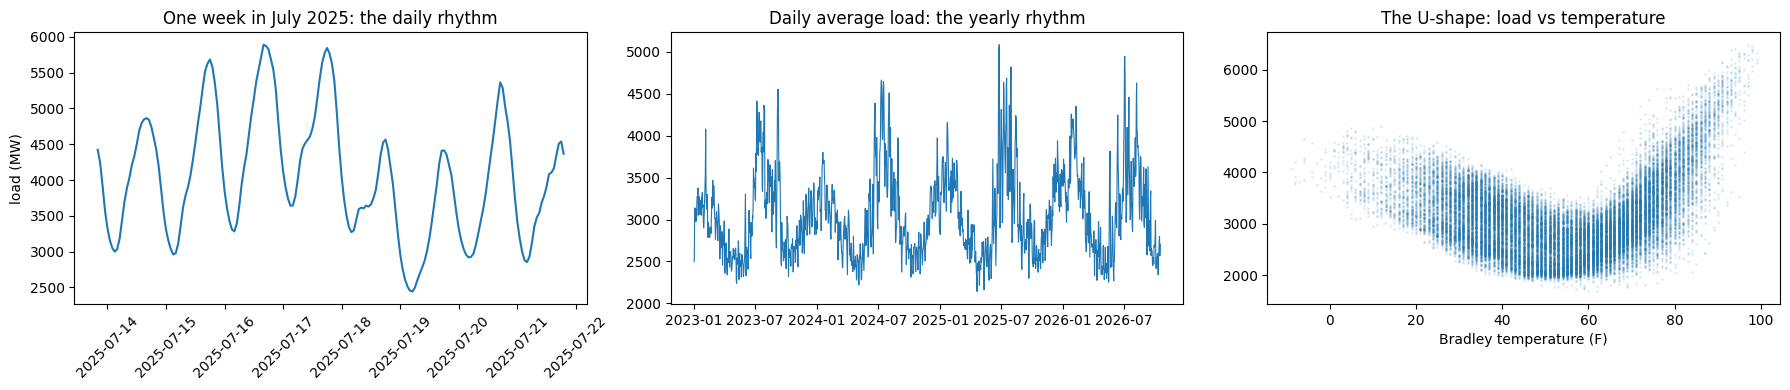

In [3]:
local = df.index.tz_convert("America/New_York")
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

week = df.loc["2025-07-14":"2025-07-21", "load_mw"]
axes[0].plot(week.index.tz_convert("America/New_York"), week.values)
axes[0].set_title("One week in July 2025: the daily rhythm")
axes[0].set_ylabel("load (MW)")
axes[0].tick_params(axis="x", rotation=45)

daily = df["load_mw"].resample("D").mean()
axes[1].plot(daily.index, daily.values, linewidth=0.8)
axes[1].set_title("Daily average load: the yearly rhythm")

axes[2].scatter(df["temp_f"], df["load_mw"], s=1, alpha=0.1)
axes[2].set_title("The U-shape: load vs temperature")
axes[2].set_xlabel("Bradley temperature (F)")
plt.tight_layout()
plt.show()

## Part 3 · Turn it into sequences
Same idea as `split_sequences` in Module 4: one big table with **one row per hour**, then a window slides down it and
every position of the window is one sample.

**The table.** 15 columns, with the load **last** (like Demand in Module 4):

| Columns | What |
| :-- | :-- |
| `temp_f` ... `cloud_cover_pct` (5) | the weather at Bradley |
| `hour_sin` ... `is_holiday` (8) | the calendar: hour of day, day of week and time of year (as a sine and a cosine, so 11 PM sits next to midnight), plus weekend and holiday flags |
| `load_known` | 1 when we know the load for that hour, 0 when we don't |
| `load_mw` | Connecticut's load: the thing we forecast |

**One sample = one forecast**, made at **issue hour T** (the hour we're in right now). It's a window of 192 rows:

| Rows | Hours | Weather | Calendar | `load_known` | `load_mw` |
| :-- | :-- | :-- | :-- | :-- | :-- |
| 1-168 | the past week (T-168 ... T-1) | 0 (not used: the load already shows it) | yes | 1 | the real load |
| skipped | hour T | | | | not over yet, so we don't know it |
| 169-192 | the next 24 hours (T+1 ... T+24) | the weather forecast | yes | 0 | **0 (hidden: this is the answer)** |

The answer `y` is the 24 hidden loads. In training, the "weather forecast" is the weather that actually happened. In the
cloud the model gets a real forecast, which is less accurate (Part 2 deals with that).

Every number is **scaled** (subtract the mean, divide by the standard deviation) with numbers from the **training years
only**, and those numbers are saved with the model so the cloud scales new data exactly the same way.

In [4]:
WEATHER = ["temp_f", "dewpoint_f", "rel_humidity_pct", "wind_speed_mph", "cloud_cover_pct"]
CALENDAR = ["hour_sin", "hour_cos", "dow_sin", "dow_cos", "doy_sin", "doy_cos", "is_weekend", "is_holiday"]
COLUMNS = WEATHER + CALENDAR + ["load_known", "load_mw"]     # the load LAST, like Demand in Module 4
HOLIDAYS = USFederalHolidayCalendar().holidays(start="2020-01-01", end="2030-12-31")


def calendar_features(hours_utc):
    """Hour of day, day of week and time of year as sines and cosines, plus weekend and holiday flags, in Connecticut time."""
    local = pd.DatetimeIndex(hours_utc).tz_convert("America/New_York")
    out = pd.DataFrame(index=pd.DatetimeIndex(hours_utc))
    out["hour_sin"] = np.sin(2 * np.pi * local.hour / 24)
    out["hour_cos"] = np.cos(2 * np.pi * local.hour / 24)
    out["dow_sin"] = np.sin(2 * np.pi * local.dayofweek / 7)
    out["dow_cos"] = np.cos(2 * np.pi * local.dayofweek / 7)
    out["doy_sin"] = np.sin(2 * np.pi * local.dayofyear / 365.25)
    out["doy_cos"] = np.cos(2 * np.pi * local.dayofyear / 365.25)
    out["is_weekend"] = (local.dayofweek >= 5).astype(float)
    out["is_holiday"] = local.tz_localize(None).normalize().isin(HOLIDAYS).astype(float)
    return out

In [5]:
# the scaling numbers come from the TRAINING years only (2023-2024), so nothing from 2025 or 2026 leaks in
train_years = df.loc[:"2024-12-31"]
card = {
    "model_type": "keras_lstm",
    "lookback_hours": SETTINGS["lookback_hours"],
    "horizon_hours": SETTINGS["horizon_hours"],
    "columns": COLUMNS,
    "load_mean": float(train_years["load_mw"].mean()),
    "load_std": float(train_years["load_mw"].std()),
    "weather_mean": {},
    "weather_std": {},
}
for column in WEATHER:
    card["weather_mean"][column] = float(train_years[column].mean())
    card["weather_std"][column] = float(train_years[column].std())

# the big table: one row per hour, every column scaled
table = calendar_features(df.index)
for column in WEATHER:
    table[column] = (df[column] - card["weather_mean"][column]) / card["weather_std"][column]
table["load_known"] = 1.0
table["load_mw"] = (df["load_mw"] - card["load_mean"]) / card["load_std"]
table = table[COLUMNS]
print(table.shape)
table.head()

(33215, 15)


,temp_f,dewpoint_f,rel_humidity_pct,wind_speed_mph,cloud_cover_pct,hour_sin,hour_cos,dow_sin,dow_cos,doy_sin,doy_cos,is_weekend,is_holiday,load_known,load_mw
2023-01-01 05:00:00+00:00,-0.244360,0.340620,1.382402,0.420981,1.093807,0.000000,1.000000,-0.781831,0.62349,0.017202,0.999852,1.0,0.0,1.0,-0.944874
2023-01-01 06:00:00+00:00,-0.244360,0.396051,1.546529,0.196425,1.093807,0.258819,0.965926,-0.781831,0.62349,0.017202,0.999852,1.0,0.0,1.0,-1.107158
2023-01-01 07:00:00+00:00,-0.244360,0.396051,1.546529,0.196425,1.093807,0.500000,0.866025,-0.781831,0.62349,0.017202,0.999852,1.0,0.0,1.0,-1.244651
2023-01-01 08:00:00+00:00,-0.357554,0.340620,1.751686,-1.457125,0.383806,0.707107,0.707107,-0.781831,0.62349,0.017202,0.999852,1.0,0.0,1.0,-1.307291
2023-01-01 09:00:00+00:00,-0.357554,0.229758,1.377273,-0.742628,-0.496595,0.866025,0.500000,-0.781831,0.62349,0.017202,0.999852,1.0,0.0,1.0,-1.325222


**The window-making function.** `split_window` is `split_sequences` from Module 4 with one twist: the window also
holds the **next 24 hours** (their weather and calendar), with the load hidden.

In [6]:
def split_window(block, lookback, horizon):
    """One sample per issue hour T, like split_sequences in Module 4.
    X = the past week (T-168 ... T-1) stacked on top of the next 24 hours (T+1 ... T+24), future load hidden
    y = the load for the next 24 hours (the answer)"""
    values = block.values.astype("float32")
    X, y, issue_hours = [], [], []
    for i in range(len(values) - lookback - horizon):
        past = values[i:i+lookback].copy()                          # the past week
        past[:, 0:len(WEATHER)] = 0.0                                # no past weather (the load already shows it)
        future = values[i+lookback+1:i+lookback+1+horizon].copy()   # the next 24 hours (hour T is skipped: not over yet)
        answer = future[:, -1].copy()                                # the load we want to predict
        future[:, -2] = 0.0                                          # load_known = 0
        future[:, -1] = 0.0                                          # hide the load
        window = np.vstack([past, future])                           # 168 + 24 = 192 rows
        if np.isnan(window).any() or np.isnan(answer).any():
            continue                                                 # skip windows with a missing hour
        X.append(window)
        y.append(answer)
        issue_hours.append(block.index[i+lookback])
    return np.array(X), np.array(y), pd.DatetimeIndex(issue_hours)

**Train, validation and test: three blocks of time, in order.** Each block makes its own windows, so no window ever
crosses from one block into the next.

| Block | Years | Used for |
| :-- | :-- | :-- |
| train | 2023-2024 | `model.fit` learns from these (`X_train`, `y_train`) |
| validation | 2025 | early stopping watches these to decide when to stop (`X_valid`, `y_valid`) |
| test | 2026 | scored once, at the very end, like a brand-new year (`X_test`, `y_test`) |

Why not a random split? Hour 5 PM and hour 6 PM look almost the same, so a random split would hide near-copies of the
test hours in the training set and the score would look far better than it really is (**data leakage**). A time series
splits by time.

In [7]:
lookback = SETTINGS["lookback_hours"]
horizon = SETTINGS["horizon_hours"]

start = time.time()
X_train, y_train, issue_hours_train = split_window(table.loc[:"2024-12-31"], lookback, horizon)
X_valid, y_valid, issue_hours_valid = split_window(table.loc["2025-01-01":"2025-12-31"], lookback, horizon)
X_test, y_test, issue_hours_test = split_window(table.loc["2026-01-01":], lookback, horizon)
print(f"built in {time.time() - start:.0f} s")
print("X_train:", X_train.shape, "  y_train:", y_train.shape, " <- 24 answers per sample, like Dense(24) in Module 4")
print("X_valid:", X_valid.shape, "  y_valid:", y_valid.shape)
print("X_test: ", X_test.shape, "  y_test: ", y_test.shape)

built in 2 s
X_train: (17347, 192, 15)   y_train: (17347, 24)  <- 24 answers per sample, like Dense(24) in Module 4
X_valid: (8568, 192, 15)   y_valid: (8568, 24)
X_test:  (6724, 192, 15)   y_test:  (6724, 24)


**The contract with the cloud: `make_window`.** Every hour, your cloud function builds **one** window for the hour it
is in, with this exact function (it is copied word for word into `forecast-24h-dl`). It makes the same 192 rows as
`split_window`, just for one issue hour, straight from the live load and the weather forecast. The check below builds
a few test windows both ways and makes sure they match. If you change one (new columns, a longer look-back), change
the other, and the one in your cloud function too.

In [8]:
def make_window(issue_hour_utc, load, weather, card):
    """The model's ONE input for ONE forecast issued at issue_hour_utc: a table with one row per hour and the
    columns in card["columns"].
    Rows 1-168: the past week. The load is known (load_known = 1); the weather columns are 0.
    Rows 169-192: the next 24 hours. The weather forecast and the calendar are filled in; the load is hidden
    (load_known = 0, load_mw = 0), because that is what the model predicts."""
    issue = pd.Timestamp(issue_hour_utc)
    past_hours = pd.date_range(issue - pd.Timedelta(hours=card["lookback_hours"]), periods=card["lookback_hours"], freq="h")
    future_hours = pd.date_range(issue + pd.Timedelta(hours=1), periods=card["horizon_hours"], freq="h")

    past = calendar_features(past_hours)
    for column in WEATHER:
        past[column] = 0.0
    past["load_known"] = 1.0
    past["load_mw"] = (load.reindex(past_hours).values - card["load_mean"]) / card["load_std"]

    future = calendar_features(future_hours)
    for column in WEATHER:
        future[column] = (weather[column].reindex(future_hours).values - card["weather_mean"][column]) / card["weather_std"][column]
    future["load_known"] = 0.0
    future["load_mw"] = 0.0

    window = pd.concat([past, future])
    return window[card["columns"]].values.astype("float32")


# the check: 5 test windows built by make_window must match the ones split_window built
load = df["load_mw"]
weather = df[WEATHER]
rng = np.random.default_rng(SETTINGS["seed"])
for k in rng.choice(len(X_test), 5, replace=False):
    window = make_window(issue_hours_test[k], load, weather, card)
    if not np.allclose(window, X_test[k], atol=1e-5):
        raise ValueError("make_window does not match split_window at " + str(issue_hours_test[k]))
print("5 random test windows: make_window == split_window")

5 random test windows: make_window == split_window


**One sample, up close.** Rows 1-168 hold the past week of load; rows 169-192 hold the next day's weather, with the
load hidden (0). The model has to fill in that hidden part.

issued at 2023-01-08 05:00:00+00:00 | shape (192, 15)


,temp_f,dewpoint_f,rel_humidity_pct,wind_speed_mph,cloud_cover_pct,hour_sin,hour_cos,dow_sin,dow_cos,doy_sin,doy_cos,is_weekend,is_holiday,load_known,load_mw
0,0.00,0.00,0.00,0.00,0.00,0.00,1.00,-0.78,0.62,0.02,1.00,1.0,0.0,1.0,-0.94
1,0.00,0.00,0.00,0.00,0.00,0.26,0.97,-0.78,0.62,0.02,1.00,1.0,0.0,1.0,-1.11
166,0.00,0.00,0.00,0.00,0.00,-0.50,0.87,-0.97,-0.22,0.12,0.99,1.0,0.0,1.0,-0.01
167,0.00,0.00,0.00,0.00,0.00,-0.26,0.97,-0.97,-0.22,0.12,0.99,1.0,0.0,1.0,-0.26
168,-1.38,-1.22,-0.01,-0.27,-1.21,0.26,0.97,-0.78,0.62,0.14,0.99,1.0,0.0,0.0,0.00
169,-1.33,-1.22,-0.13,0.89,-0.50,0.50,0.87,-0.78,0.62,0.14,0.99,1.0,0.0,0.0,0.00
190,-1.55,-1.22,0.43,-0.52,-1.21,-0.26,0.97,-0.78,0.62,0.14,0.99,1.0,0.0,0.0,0.00
191,-1.66,-1.22,0.76,-1.46,0.38,0.00,1.00,0.00,1.00,0.15,0.99,0.0,0.0,0.0,0.00


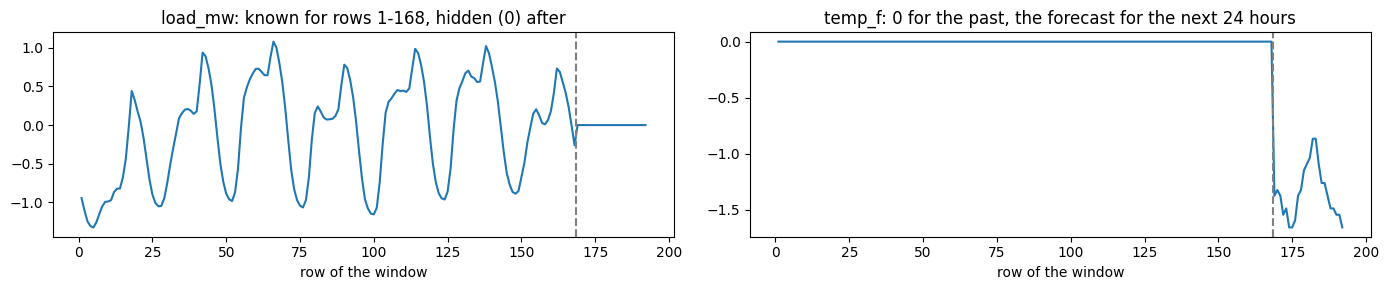

In [9]:
sample = pd.DataFrame(X_train[0], columns=COLUMNS)
print("issued at", issue_hours_train[0], "| shape", X_train[0].shape)
display(sample.iloc[[0, 1, 166, 167, 168, 169, 190, 191]].round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 3))
axes[0].plot(range(1, 193), sample["load_mw"])
axes[0].axvline(168.5, color="gray", linestyle="--")
axes[0].set_title("load_mw: known for rows 1-168, hidden (0) after")
axes[0].set_xlabel("row of the window")
axes[1].plot(range(1, 193), sample["temp_f"])
axes[1].axvline(168.5, color="gray", linestyle="--")
axes[1].set_title("temp_f: 0 for the past, the forecast for the next 24 hours")
axes[1].set_xlabel("row of the window")
plt.tight_layout()
plt.show()

## Part 4 · The baseline to beat
**Same hour yesterday**: the load at 5 PM tomorrow will be about what it was at 5 PM today. It costs nothing, and it
is the yardstick the leaderboard uses. The leaderboard splits every forecast into four **lead blocks** (1-6, 7-12,
13-18 and 19-24 hours ahead) and averages them.

In [10]:
def mae_by_block(errors):
    """Mean absolute error for each lead block, from an array of absolute errors shaped (samples, 24)."""
    blocks = {"1-6 h": slice(0, 6), "7-12 h": slice(6, 12), "13-18 h": slice(12, 18), "19-24 h": slice(18, 24)}
    out = {}
    for name in blocks:
        out[name] = float(errors[:, blocks[name]].mean())
    return out


actual_test = y_test * card["load_std"] + card["load_mean"]     # back to MW
baseline_test = []
for issue in issue_hours_test:
    target_hours = pd.date_range(issue + pd.Timedelta(hours=1), periods=horizon, freq="h")
    baseline_test.append(load.reindex(target_hours - pd.Timedelta(hours=24)).values)
baseline_test = np.array(baseline_test)
baseline_blocks = mae_by_block(np.abs(baseline_test - actual_test))
print("same hour yesterday, 2026, average error by lead block (MW):")
for name in baseline_blocks:
    print(f"   {name}: {baseline_blocks[name]:.0f}")

same hour yesterday, 2026, average error by lead block (MW):
   1-6 h: 268
   7-12 h: 268
   13-18 h: 268
   19-24 h: 268


## Part 5 · Build and fit the LSTM
The same recipe as the multi-output model at the end of Module 4 (`M4_3e`): a `Sequential` model, one LSTM that reads
the 192 rows in order, and a `Dense(24)` layer that writes **the whole next day in one shot**, one output per hour.

The loss is the mean absolute error, the same thing we score.

In [11]:
keras.utils.set_random_seed(SETTINGS["seed"])          # re-seed before every build: same starting weights every run

model = Sequential()
model.add(Input(shape=(X_train.shape[1], X_train.shape[2])))   # 192 hours x 15 columns
model.add(LSTM(SETTINGS["units"]))                              # reads the 192 hours in order
model.add(Dense(horizon))                                       # 24 outputs: the next 24 hours, in one shot
model.compile(optimizer="adam", loss="mae")
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        20,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 24)             │         1,560 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,040 (86.09 KB)

 Trainable params: 22,040 (86.09 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30


136/136 - 31s - 231ms/step - loss: 0.4412 - val_loss: 0.3107


Epoch 2/30


136/136 - 42s - 305ms/step - loss: 0.2129 - val_loss: 0.2487


Epoch 3/30


136/136 - 31s - 227ms/step - loss: 0.1743 - val_loss: 0.2182


... (27 outputs left out)

136/136 - 30s - 221ms/step - loss: 0.0972 - val_loss: 0.1687


Epoch 18/30


136/136 - 41s - 300ms/step - loss: 0.0959 - val_loss: 0.1688


fit in 614 s


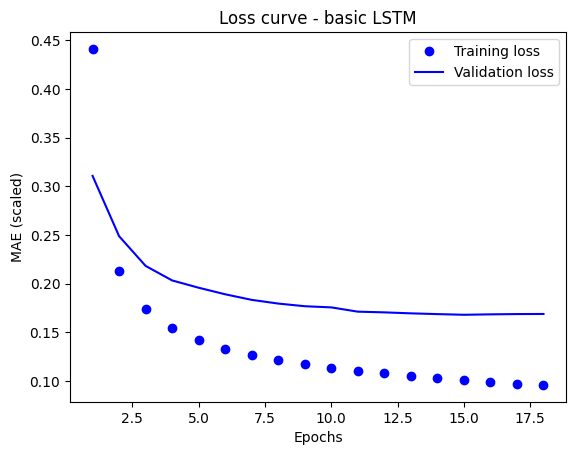

epochs run: 18 | best validation loss: 0.168 at epoch 15


In [12]:
early_stop = EarlyStopping(monitor="val_loss", patience=SETTINGS["patience"], restore_best_weights=True)
start = time.time()
history = model.fit(X_train, y_train,                           # 2023-2024
                    validation_data=(X_valid, y_valid),          # 2025: early stopping watches it
                    epochs=SETTINGS["epochs"],
                    batch_size=SETTINGS["batch_size"],
                    callbacks=[early_stop],
                    verbose=2)
print(f"fit in {time.time() - start:.0f} s")

# loss curve - always look at this after a fit!
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = range(1, len(loss) + 1)
plt.plot(epochs, loss, "bo", label="Training loss")
plt.plot(epochs, val_loss, "b", label="Validation loss")
plt.title("Loss curve - basic LSTM")
plt.xlabel("Epochs")
plt.ylabel("MAE (scaled)")
plt.legend()
plt.show()
print("epochs run:", len(loss), "| best validation loss:", round(min(val_loss), 4), "at epoch", val_loss.index(min(val_loss)) + 1)

## Part 6 · Score it like the leaderboard
On 2026, which the model never saw. Each column is an **average error** in MW: how far off the forecasts were,
on average, for that lead block. **Skill** = 1 - (your error / the baseline's error) in each lead block, averaged
over the four blocks. 0 means no better than "same hour yesterday"; 1 would be perfect.

In [13]:
pred_test = model.predict(X_test, verbose=0) * card["load_std"] + card["load_mean"]     # back to MW
lstm_blocks = mae_by_block(np.abs(pred_test - actual_test))
rows = []
skills = []
for name in lstm_blocks:
    skill = 1 - lstm_blocks[name] / baseline_blocks[name]
    skills.append(skill)
    rows.append({"lead block": name, "same hour yesterday: avg error (MW)": round(baseline_blocks[name]),
                 "LSTM: avg error (MW)": round(lstm_blocks[name]), "skill": round(skill, 3)})
scoreboard = pd.DataFrame(rows)
print("average skill over the four lead blocks:", round(float(np.mean(skills)), 3))
scoreboard

average skill over the four lead blocks: 0.505


,lead block,same hour yesterday: avg error (MW),LSTM: avg error (MW),skill
0,1-6 h,268,137,0.489
1,7-12 h,268,135,0.496
2,13-18 h,268,127,0.526
3,19-24 h,268,132,0.508


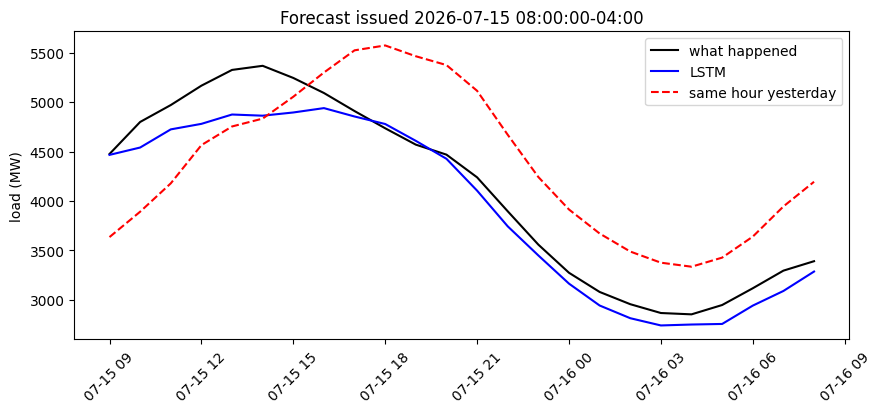

In [14]:
# one forecast up close: issued at 8 AM Connecticut time on a summer day in 2026
issue_local = pd.Timestamp("2026-07-15 08:00", tz="America/New_York")
k = int(np.argmin(np.abs((issue_hours_test - issue_local.tz_convert("UTC")).total_seconds())))
target_hours = pd.date_range(issue_hours_test[k] + pd.Timedelta(hours=1), periods=horizon, freq="h").tz_convert("America/New_York")
plt.figure(figsize=(10, 4))
plt.plot(target_hours, actual_test[k], "k-", label="what happened")
plt.plot(target_hours, pred_test[k], "b-", label="LSTM")
plt.plot(target_hours, baseline_test[k], "r--", label="same hour yesterday")
plt.title("Forecast issued " + str(issue_hours_test[k].tz_convert("America/New_York")))
plt.ylabel("load (MW)")
plt.legend()
plt.xticks(rotation=45)
plt.show()

## Part 7 · Save it for the cloud
Two files go to your Google Cloud bucket: the model (`model.keras`) and the **model card** (`model_card.json`), which
holds the look-back, the horizon, the column list and the scaling numbers so the cloud function builds the window
exactly the way you did. The card's `range_method` is `none` for now: this model makes one forecast per hour, no range.
Part 2 changes that.

Part 8 uploads both files to your bucket.

In [15]:
card["range_method"] = "none"
card["trained_at"] = pd.Timestamp.now(tz="UTC").strftime("%Y-%m-%dT%H:%M:%SZ")
card["test_skill_2026"] = round(float(np.mean(skills)), 3)
card["test_mae_mw"] = round(float(np.mean(np.abs(pred_test - actual_test))), 1)     # the leaderboard's "Test-year MAE"
model.save("model.keras")
with open("model_card.json", "w") as f:
    json.dump(card, f, indent=1)

# prove the saved files give the same answer
reloaded = load_model("model.keras")
check = reloaded.predict(X_test[:5], verbose=0) * card["load_std"] + card["load_mean"]
print("reloaded model reproduces the predictions:", bool(np.allclose(check, pred_test[:5], atol=0.5)))
print("saved: model.keras and model_card.json")

reloaded model reproduces the predictions: True
saved: model.keras and model_card.json


## Part 8 · Ship it to your energy project
Your energy project on Google Cloud (built once with the
[Energy Project Setup Guide](https://github.com/drdave-teaching/OPIM5509-notebooks/blob/main/FinalProject/Energy_Project_Setup_5509.ipynb)) runs **`forecast-24h-dl`** every hour at :20. It loads
`energy/models/model.keras` and `model_card.json` from your bucket, builds the input table with the same `make_window` as
this notebook (the last week of live load from your `scraper-isone`, and the newest HRRR weather forecasts from
Dr. Dave's class file, or the National Weather Service forecast your `scraper-weather-forecast` saves if that file is
ever missing), and writes the next 24 hours to `energy/forecasts/latest.csv`.

**Once, before the first deploy:** on your fork, Settings > Secrets and variables > Actions > Variables, add
`COURSE` = `5509`, then Actions > "Deploy forecast-24h-dl" > Run workflow. (Without `COURSE`, that workflow stops
with a message and changes nothing.)

**Deep learning only.** The forecast that goes live must come from `model.predict` on a **Keras network you trained**
(LSTM, GRU, Conv1D, Dense, Bidirectional, or a stack of them), saved as `model.keras` and run by `forecast-24h-dl`.
**Keras models only:** no scikit-learn, gradient boosting, random or quantile forests, XGBoost, statsmodels or
hand-written rules in production (they are fine as a baseline in your report), and don't deploy 5512's `forecast-24h`. An ensemble is fine if it is one Keras model (several networks averaged inside one `model.keras`).
You may change `make_window` in the cloud function (keep it the same as your notebook), but not how the forecast is
made. The 5509 leaderboard only scores forecasts made by `forecast-24h-dl` with a Keras network: it reads the
`run_summary.json` that the function writes every hour, which lists your network's layers.

Type your project ID, set `UPLOAD = True`, and run the cells below. When the **"Allow access"** pop-up opens,
pick the **Gmail you used for Google Cloud**.

In [16]:
PROJECT_ID = "YOUR-ENERGY-PROJECT-ID"
BUCKET_NAME = PROJECT_ID              # your bucket has the same name as your project (setup guide)
UPLOAD = False                       # True once your energy project is set up

if UPLOAD and ("YOUR-ENERGY-PROJECT-ID" in PROJECT_ID or "YOUR-ENERGY-PROJECT-ID" in BUCKET_NAME):
    print("Type your PROJECT_ID and BUCKET_NAME above, then re-run this cell.")
    UPLOAD = False

if UPLOAD:
    from google.colab import auth
    from google.cloud import storage
    auth.authenticate_user()

    # CHECK 1: which Google account did you just pick in the pop-up?
    account_lines = !gcloud config get-value account
    signed_in_as = "unknown"
    if len(account_lines) > 0:
        signed_in_as = account_lines[-1].strip()
    print("1. Signed in as:", signed_in_as)

    # CHECK 2: can that account see your bucket?
    client = storage.Client(project=PROJECT_ID)
    bucket = client.bucket(BUCKET_NAME)
    try:
        bucket_ok = bucket.exists()
    except Exception as err:
        bucket_ok = False
        print("   Google says:", str(err)[:200])
    if not bucket_ok:
        raise RuntimeError("The account " + signed_in_as + " cannot see the bucket " + BUCKET_NAME + ". "
                           "Check BUCKET_NAME, or Runtime > Disconnect and delete runtime, then run again "
                           "and pick your Google Cloud Gmail in the pop-up.")
    print("2. Bucket found:", BUCKET_NAME)

    # CHECK 3: is forecast-24h-dl deployed?
    state_lines = !gcloud functions describe forecast-24h-dl --gen2 --region=us-central1 --project={PROJECT_ID} --format="value(state)"
    state = "NOT FOUND"
    if len(state_lines) > 0 and state_lines[-1].strip() in ["ACTIVE", "DEPLOYING", "FAILED"]:
        state = state_lines[-1].strip()
    print("3. forecast-24h-dl:", state)
    if state != "ACTIVE":
        print("   Add the repository variable COURSE = 5509, run 'Deploy forecast-24h-dl' on your fork's Actions tab, wait for green, then re-run this cell.")
else:
    print("UPLOAD is False: nothing is uploaded (the model is saved in this Colab session only).")

UPLOAD is False: nothing is uploaded (the model is saved in this Colab session only).


**Upload.** `energy/models/model.keras` is the **live** model (replaced every time you ship);
`energy/models/history/` keeps a copy of every model you ever shipped, named by time.

In [17]:
if UPLOAD:
    bucket.blob("energy/models/model.keras").upload_from_filename("model.keras")
    bucket.blob("energy/models/model_card.json").upload_from_filename("model_card.json")
    stamp = card["trained_at"].replace(":", "-")
    bucket.blob("energy/models/history/model_" + stamp + ".keras").upload_from_filename("model.keras")
    bucket.blob("energy/models/history/model_card_" + stamp + ".json").upload_from_filename("model_card.json")
    print("Live model:  gs://" + BUCKET_NAME + "/energy/models/model.keras", "| range_method:", card["range_method"])
    print("Kept a copy: gs://" + BUCKET_NAME + "/energy/models/history/model_" + stamp + ".keras")
else:
    print("UPLOAD is False: skipping.")

UPLOAD is False: skipping.


**Run it now.** Normally it runs by itself every hour at :20. This cell starts it right now, then checks your bucket
every 15 seconds and shows the forecast.

In [18]:
if UPLOAD:
    from datetime import datetime, timezone
    started = datetime.now(timezone.utc)
    !gcloud scheduler jobs run forecast-24h-dl-hourly --location=us-central1 --project={PROJECT_ID}
    print("Started forecast-24h-dl. Waiting for your forecast", end="")
    latest_blob = bucket.blob("energy/forecasts/latest.csv")
    ready = False
    for attempt in range(20):                 # every 15 seconds, for up to 5 minutes
        time.sleep(15)
        print(".", end="")
        if latest_blob.exists():
            latest_blob.reload()
            if latest_blob.updated > started:
                ready = True
                break
    print()
    if ready:
        import io
        latest = pd.read_csv(io.BytesIO(latest_blob.download_as_bytes()))
        print(latest[["target_hour_utc", "predicted_low_mw", "predicted_load_mw", "predicted_high_mw", "range_method"]].head(6))
    else:
        print("No new forecast after 5 minutes. Run the log cell below and paste the log into Claude.")
else:
    print("UPLOAD is False: skipping.")

UPLOAD is False: skipping.


**Optional, only for troubleshooting.** `"no_load_data"` means your ISO-NE secrets are missing or the scraper has not
collected a full week yet; `"no_model"` means the upload didn't run; `"bad_card"` explains what the card is missing;
anything with `Error` is worth pasting into Claude. A `range_method` ending in `_nws` means the class HRRR file was
missing, so the National Weather Service forecast was used instead (that's fine).

In [19]:
if UPLOAD:
    !gcloud functions logs read forecast-24h-dl --region=us-central1 --gen2 --limit=20 --project={PROJECT_ID}
else:
    print("UPLOAD is False: no log to read.")

UPLOAD is False: no log to read.


## Part 9 · Join the 5509 leaderboard (once)
Dr. Dave's collector copies every 5509 student's forecasts into one class table every hour, freezes them before the
hour they predict, and scores them on the **OPIM 5509 leaderboard** (deep learning only, so your LSTM is compared
with other neural networks, not with 5512's machine learning models). It needs **read-only** access to your bucket:
it can read your files, never change or delete them, and it can't touch anything else in your project.

Type your NetID and a **nickname** (what the public leaderboard shows instead of your name: keep it class-friendly, no
commas), run the cell, and paste the line it prints into **"Join the 5509 leaderboard"** in HuskyCT (Final Project
Materials), by Friday, November 20. You only do this once: your Part 2 model ships to the same bucket and is scored the same way.

In [20]:
NETID = "abc12345"            # <-- your UConn NetID, lower case
NICKNAME = "Long Short-Term Mo"   # <-- what the leaderboard shows (up to 24 characters)
COLLECTOR = "collector@opim5512-collector-f26.iam.gserviceaccount.com"     # Dr. Dave's class collector (both courses)

if UPLOAD:
    !gcloud storage buckets add-iam-policy-binding gs://{BUCKET_NAME} --member=serviceAccount:{COLLECTOR} --role=roles/storage.objectViewer --project={PROJECT_ID} --format=none
    print("Shared gs://" + BUCKET_NAME + " (read-only) with Dr. Dave's collector.")
    print()
    print("Paste this line into 'Join the 5509 leaderboard' in HuskyCT (Final Project Materials):")
    print(NETID.strip().lower() + "," + BUCKET_NAME + "," + NICKNAME.replace(",", " ").strip()[:24])
    print()
    print("OPIM 5509 leaderboard (your first scored hour shows up the hour after your line is on the roster):")
    print("https://storage.googleapis.com/opim5509-leaderboard-f26/index.html")
else:
    print("UPLOAD is False: nothing shared.")

UPLOAD is False: nothing shared.


## Your turn
This notebook is simple on purpose: ship this basic model first, so your forecast is live early. Then make it better:
* **Tune it:** [`FP1b_Tune_Your_LSTM`](https://colab.research.google.com/github/drdave-teaching/OPIM5509-notebooks/blob/main/FinalProject/FP1b_Tune_Your_LSTM.ipynb)
  tunes the network in rounds (a convolution and pooling, stacked layers, sizes, GRU vs. LSTM, dropout), picks the
  winner on 2025, shows it on the 2026 holdout, and ships it if it beats this one.
* **Sequence length and columns:** a shorter or longer look-back (`lookback_hours` = 48 or 336; the card carries it to
  the cloud), or new columns. New columns change `split_window` and `make_window`, so change `make_window` in your cloud
  function too.
* **Using Claude for any of this?** Good, but read what it writes and test it: check the shapes, keep the "make_window ==
  split_window" check passing, and compare the new model with this one on the same 2025 hours before you
  ship. You have to explain every layer in your report.
* **New features:** more airports (Hartford, New Haven, Groton, or nearby New York and Massachusetts stations), heating
  and cooling degree hours, the weather a few hours earlier. For production you also need those forecasts every hour,
  so this means building your own data pipeline (the `hefty` package can fetch HRRR forecasts for any location).

**Keras models only** in production.